<a href="https://colab.research.google.com/github/bdipesh3045/Data-Science-project-AI-Class-/blob/main/Final_tensorflow_wandb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sign Language Recognition using an MLP
A simple TensorFlow notebook for AI class. Train on the training file. Split the official test file in half: the validation half picks the best setting, and the test half gives the final score.

The input is 784 grayscale pixels (28 × 28). Hidden layers learn patterns; softmax gives a probability for each letter. This dataset contains 24 static letters: J and Z are excluded.

**Every run is tracked in Weights & Biases**, together with our week 1 SVM and a CNN, to build the week 2 dashboard.

In [1]:
%pip install -q kagglehub tensorflow scikit-learn matplotlib pandas wandb

## 1. Import libraries

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
import tensorflow as tf
import wandb
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, hinge_loss, ConfusionMatrixDisplay

keras.utils.set_random_seed(42)

## 1b. Connect to Weights & Biases
When asked, paste your API key from wandb.ai/authorize. All runs go to one project, so they appear on the same dashboard.

In [3]:
wandb.login()
PROJECT = "sign-language-week2"


# Sends loss and accuracy to W&B at the end of every epoch
class WandbLogger(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        wandb.log({"epoch": epoch + 1,
                   "train_loss": logs["loss"], "train_acc": logs["accuracy"],
                   "val_loss": logs["val_loss"], "val_acc": logs["val_accuracy"]})

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: zimbapalden2006-gmail-com (zimbapalden2006-gmail-com-university-of-louisiana-monroe) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


## 2. Load and prepare the data
Divide pixel values by 255 to put them between 0 and 1.

**Why validation comes from the test file.** The training file was built by taking each hand photo and making many small variations of it (tiny rotations, brightness changes, blur filters). If we pick validation rows at random from the training file, almost every validation image has a near twin in training. The model just recognizes the twin, so validation shows 100% while the real accuracy is much lower (our first run: 100% validation, 79% test). The official test file does not share those twins with training, so it gives an honest check.

We split the test file in half so the final test score is never used to pick the model. The two halves may share twins with each other, so the final score can be slightly optimistic.

In [4]:
data_path = Path(kagglehub.dataset_download("datamunge/sign-language-mnist"))
train_df = pd.read_csv(next(data_path.rglob("sign_mnist_train.csv")))
test_df = pd.read_csv(next(data_path.rglob("sign_mnist_test.csv")))

# Convert the original letter labels into consecutive numbers 0 to 23.
# The original labels skip J (9), so they are not consecutive.
labels = sorted(train_df["label"].unique())
letters = [chr(65 + int(label)) for label in labels]
label_map = {label: i for i, label in enumerate(labels)}

# Train on the whole training file.
X_train = train_df.drop(columns="label").to_numpy(dtype="float32") / 255.0
y_train = train_df["label"].map(label_map).to_numpy()

# Validation comes from the test file, not the training file (see note above).
X_holdout = test_df.drop(columns="label").to_numpy(dtype="float32") / 255.0
y_holdout = test_df["label"].map(label_map).to_numpy()
X_val, X_test, y_val, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.5, random_state=42, stratify=y_holdout
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)
print("Letters:", letters)

Using Colab cache for faster access to the 'sign-language-mnist' dataset.
Training: (27455, 784)
Validation: (3586, 784)
Testing: (3586, 784)
Letters: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']


## 3. Create the model
One small function lets us change the hidden layers, activation, and learning rate. Integer labels use sparse categorical crossentropy.

In [5]:
def build_model(hidden_layers, activation, learning_rate):
    model = keras.Sequential()
    model.add(keras.Input(shape=(784,)))

    for neurons in hidden_layers:
        model.add(keras.layers.Dense(neurons, activation=activation))

    model.add(keras.layers.Dense(len(letters), activation="softmax"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

build_model([512, 256, 128], "relu", 0.001).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 569,240 (2.17 MB)

 Trainable params: 569,240 (2.17 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Compare model settings
Choose the model using validation accuracy only. Early stopping restores the weights with the best validation accuracy and stops after four epochs without improvement. Each run uses the same split and seed; results can still vary across hardware.

Each run is logged to W&B (loss and accuracy every epoch, plus its settings).

In [6]:
experiments = [
    # Name, hidden layers, activation, learning rate
    ("1 hidden layer", [512], "relu", 0.001),
    ("2 hidden layers", [512, 256], "relu", 0.001),
    ("Baseline", [512, 256, 128], "relu", 0.001),
    ("Tanh", [512, 256, 128], "tanh", 0.001),
    ("Sigmoid", [512, 256, 128], "sigmoid", 0.001),
    ("Small", [128, 64, 32], "relu", 0.001),
    ("Large", [1024, 512, 256], "relu", 0.001),
    ("Higher learning rate", [512, 256, 128], "relu", 0.01),
    ("Lower learning rate", [512, 256, 128], "relu", 0.0001)
]

results = []
best_model = None
best_accuracy = -1

for name, hidden_layers, activation, learning_rate in experiments:
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)
    print("\nTraining:", name)
    model = build_model(hidden_layers, activation, learning_rate)

    wandb.init(project=PROJECT, name=f"MLP - {name}",
               config={"model": "MLP", "hidden_layers": hidden_layers,
                       "num_hidden_layers": len(hidden_layers),
                       "activation": activation, "learning_rate": learning_rate,
                       "batch_size": 128})

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_accuracy", mode="max", patience=4,
        restore_best_weights=True
    )
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=30, batch_size=128,
        callbacks=[early_stop, WandbLogger()], verbose=2
    )

    val_loss, val_accuracy = model.evaluate(X_val, y_val, verbose=0)
    wandb.summary["best_val_acc"] = val_accuracy
    wandb.summary["epochs_run"] = len(history.history["loss"])
    wandb.finish()

    results.append({
        "Model": name,
        "Layers": str(hidden_layers),
        "Activation": activation,
        "Learning rate": learning_rate,
        "Epochs run": len(history.history["loss"]),
        "Validation accuracy": val_accuracy
    })

    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        best_model = model
        best_history = history
        best_name = name

results_df = pd.DataFrame(results).sort_values(
    "Validation accuracy", ascending=False
)
display(results_df)
print("Best model:", best_name)


Training: 1 hidden layer


Epoch 1/30
215/215 - 5s - 23ms/step - accuracy: 0.4203 - loss: 2.0583 - val_accuracy: 0.5273 - val_loss: 1.6311
Epoch 2/30
215/215 - 1s - 3ms/step - accuracy: 0.6675 - loss: 1.1706 - val_accuracy: 0.6046 - val_loss: 1.3597
Epoch 3/30
215/215 - 1s - 3ms/step - accuracy: 0.7601 - loss: 0.8630 - val_accuracy: 0.6327 - val_loss: 1.2194
Epoch 4/30
215/215 - 1s - 3ms/step - accuracy: 0.8156 - loss: 0.6788 - val_accuracy: 0.6595 - val_loss: 1.1320
Epoch 5/30
215/215 - 1s - 3ms/step - accuracy: 0.8547 - loss: 0.5466 - val_accuracy: 0.6765 - val_loss: 1.0671
Epoch 6/30
215/215 - 1s - 3ms/step - accuracy: 0.8862 - loss: 0.4436 - val_accuracy: 0.7008 - val_loss: 1.0377
Epoch 7/30
215/215 - 1s - 3ms/step - accuracy: 0.9123 - loss: 0.3594 - val_accuracy: 0.7089 - val_loss: 1.0175
Epoch 8/30
215/215 - 1s - 3ms/step - accuracy: 0.9346 - loss: 0.2904 - val_accuracy: 0.7153 - val_loss: 1.0036
Epoch 9/30
215/215 - 1s - 3ms/step - accuracy: 0.9517 - loss: 0.2343 - val_accuracy: 0.7223 - val_loss: 0.9932


epoch,▁▁▂▂▂▂▃▃▃▄▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
train_acc,▁▄▅▆▆▇▇▇▇█████████████████
train_loss,█▅▄▃▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_acc,▁▃▄▅▆▆▆▇▇▇▇▇▇▇▇▇▇█▇▇██████
val_loss,█▅▃▃▂▁▁▁▁▁▁▁▁▂▂▂▂▂▂▃▂▂▂▂▂▃
best_val_acc,0.75878
epoch,26
epochs_run,26
train_acc,1
train_loss,0.0106
val_acc,0.75516



Training: 2 hidden layers


Epoch 1/30
215/215 - 4s - 20ms/step - accuracy: 0.4110 - loss: 1.9740 - val_accuracy: 0.5443 - val_loss: 1.5187
Epoch 2/30
215/215 - 1s - 3ms/step - accuracy: 0.6833 - loss: 1.0207 - val_accuracy: 0.6235 - val_loss: 1.1820
Epoch 3/30
215/215 - 1s - 3ms/step - accuracy: 0.7969 - loss: 0.6588 - val_accuracy: 0.6545 - val_loss: 1.0839
Epoch 4/30
215/215 - 1s - 4ms/step - accuracy: 0.8663 - loss: 0.4398 - val_accuracy: 0.6857 - val_loss: 1.0003
Epoch 5/30
215/215 - 1s - 3ms/step - accuracy: 0.9197 - loss: 0.2853 - val_accuracy: 0.7105 - val_loss: 0.9438
Epoch 6/30
215/215 - 1s - 6ms/step - accuracy: 0.9561 - loss: 0.1812 - val_accuracy: 0.7117 - val_loss: 0.9752
Epoch 7/30
215/215 - 1s - 3ms/step - accuracy: 0.9755 - loss: 0.1206 - val_accuracy: 0.7186 - val_loss: 1.0049
Epoch 8/30
215/215 - 1s - 6ms/step - accuracy: 0.9870 - loss: 0.0798 - val_accuracy: 0.7699 - val_loss: 0.9303
Epoch 9/30
215/215 - 1s - 4ms/step - accuracy: 0.9944 - loss: 0.0493 - val_accuracy: 0.7660 - val_loss: 0.9826


...


Training: Lower learning rate


Epoch 1/30
215/215 - 4s - 19ms/step - accuracy: 0.2666 - loss: 2.7030 - val_accuracy: 0.4158 - val_loss: 2.2282
Epoch 2/30
215/215 - 1s - 4ms/step - accuracy: 0.5152 - loss: 1.7881 - val_accuracy: 0.5273 - val_loss: 1.6990
Epoch 3/30
215/215 - 1s - 4ms/step - accuracy: 0.6361 - loss: 1.3492 - val_accuracy: 0.5811 - val_loss: 1.4437
Epoch 4/30
215/215 - 1s - 3ms/step - accuracy: 0.7036 - loss: 1.0913 - val_accuracy: 0.6199 - val_loss: 1.2866
Epoch 5/30
215/215 - 1s - 3ms/step - accuracy: 0.7535 - loss: 0.9107 - val_accuracy: 0.6562 - val_loss: 1.1689
Epoch 6/30
215/215 - 1s - 3ms/step - accuracy: 0.7947 - loss: 0.7750 - val_accuracy: 0.6801 - val_loss: 1.0881
Epoch 7/30
215/215 - 1s - 4ms/step - accuracy: 0.8268 - loss: 0.6687 - val_accuracy: 0.6843 - val_loss: 1.0291
Epoch 8/30
215/215 - 1s - 6ms/step - accuracy: 0.8521 - loss: 0.5812 - val_accuracy: 0.6963 - val_loss: 0.9816
Epoch 9/30
215/215 - 1s - 4ms/step - accuracy: 0.8745 - loss: 0.5063 - val_accuracy: 0.6977 - val_loss: 0.9480


epoch,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
train_acc,▁▃▅▅▆▆▆▇▇▇▇▇▇█████████████████
train_loss,█▆▄▄▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val_acc,▁▃▄▅▆▆▆▇▇▇▇▇▇▇▇▇██████████████
val_loss,█▅▄▃▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂
best_val_acc,0.76352
epoch,30
epochs_run,30
train_acc,0.99975
train_loss,0.02393
val_acc,0.76102


,Model,Layers,Activation,Learning rate,Epochs run,Validation accuracy
6,Large,"[1024, 512, 256]",relu,0.0010,12,0.827384
3,Tanh,"[512, 256, 128]",tanh,0.0010,12,0.822365
2,Baseline,"[512, 256, 128]",relu,0.0010,19,0.812326
1,2 hidden layers,"[512, 256]",relu,0.0010,16,0.799498
4,Sigmoid,"[512, 256, 128]",sigmoid,0.0010,30,0.774958
8,Lower learning rate,"[512, 256, 128]",relu,0.0001,30,0.763525
0,1 hidden layer,[512],relu,0.0010,26,0.758784
5,Small,"[128, 64, 32]",relu,0.0010,19,0.708310
7,Higher learning rate,"[512, 256, 128]",relu,0.0100,5,0.034300


Best model: Large


## 4b. Week 1 SVM in W&B (the control)
An SVM doesn't train in epochs, so this builds a **learning curve**: it trains the SVM on 20%, 40%, … 100% of the training data and logs the loss each time (at epochs 3, 6, … 15) so it appears on the same charts as the MLPs. Same settings as week 1: RBF kernel, C = 10, gamma = scale.

The SVM's loss is **hinge loss** (what an SVM optimizes), on a different scale from the MLP's cross-entropy, so compare the shapes of the loss curves and use **validation accuracy** to compare the models directly. This cell takes a few minutes.

In [7]:
wandb.init(project=PROJECT, name="SVM - RBF C=10",
           config={"model": "SVM", "kernel": "rbf", "C": 10, "gamma": "scale"})

class_ids = list(range(len(letters)))
order = np.random.default_rng(42).permutation(len(X_train))
for step in range(1, 6):
    n = int(len(X_train) * step / 5)          # 20%, 40%, ... 100% of the training data
    idx = order[:n]
    svm = SVC(kernel="rbf", C=10, gamma="scale").fit(X_train[idx], y_train[idx])
    svm_val_acc = accuracy_score(y_val, svm.predict(X_val))
    wandb.log({"epoch": step * 3, "train_examples": n,
               "train_loss": hinge_loss(y_train[idx], svm.decision_function(X_train[idx]), labels=class_ids),
               "val_loss": hinge_loss(y_val, svm.decision_function(X_val), labels=class_ids),
               "val_acc": svm_val_acc})
    print(f"{step * 20:3d}% of training data -> validation accuracy {svm_val_acc:.2%}")

wandb.summary["best_val_acc"] = svm_val_acc
wandb.finish()

 20% of training data -> validation accuracy 82.26%
 40% of training data -> validation accuracy 83.44%
 60% of training data -> validation accuracy 83.83%
 80% of training data -> validation accuracy 83.94%
100% of training data -> validation accuracy 83.85%


epoch,▁▃▅▆█
train_examples,▁▃▅▆█
train_loss,█▄▃▃▁
val_acc,▁▆███
val_loss,█▃▂▁▁
best_val_acc,0.83854
epoch,15
train_examples,27455
train_loss,1e-05
val_acc,0.83854
val_loss,0.5865


## 4c. CNN in W&B (the model we deploy)

1.   List item
2.   List item


Same data and the same W&B logging, but with convolution layers that see the image as a 28 × 28 grid. This is the architecture used in our Flask app: three Conv2D (64 filters, 3×3) + MaxPooling layers, Dense 128, Dropout 0.2.

In [8]:
def build_cnn(learning_rate=0.001):
    model = keras.Sequential([
        keras.Input(shape=(784,)),
        keras.layers.Reshape((28, 28, 1)),      # turn the 784 pixels back into an image
        keras.layers.Conv2D(64, (3, 3), activation="relu"),
        keras.layers.MaxPooling2D(2, 2),
        keras.layers.Conv2D(64, (3, 3), activation="relu"),
        keras.layers.MaxPooling2D(2, 2),
        keras.layers.Conv2D(64, (3, 3), activation="relu"),
        keras.layers.MaxPooling2D(2, 2),
        keras.layers.Flatten(),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(len(letters), activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

keras.backend.clear_session()
keras.utils.set_random_seed(42)
cnn = build_cnn()

wandb.init(project=PROJECT, name="CNN - 3 conv layers",
           config={"model": "CNN", "conv_layers": 3, "filters": 64, "dense": 128,
                   "dropout": 0.2, "activation": "relu", "learning_rate": 0.001,
                   "batch_size": 128})
cnn_history = cnn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30, batch_size=128,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                             patience=4, restore_best_weights=True),
               WandbLogger()],
    verbose=2
)
cnn_val_loss, cnn_val_acc = cnn.evaluate(X_val, y_val, verbose=0)
wandb.summary["best_val_acc"] = cnn_val_acc
wandb.summary["epochs_run"] = len(cnn_history.history["loss"])
wandb.finish()

print(f"SVM validation accuracy:      {svm_val_acc:.2%}")
print(f"Best MLP ({best_name}): {best_accuracy:.2%}")
print(f"CNN validation accuracy:      {cnn_val_acc:.2%}")

Epoch 1/30
215/215 - 15s - 68ms/step - accuracy: 0.3160 - loss: 2.2005 - val_accuracy: 0.6484 - val_loss: 1.1623
Epoch 2/30
215/215 - 1s - 7ms/step - accuracy: 0.7253 - loss: 0.8150 - val_accuracy: 0.7786 - val_loss: 0.6823
Epoch 3/30
215/215 - 1s - 6ms/step - accuracy: 0.8551 - loss: 0.4342 - val_accuracy: 0.8171 - val_loss: 0.5639
Epoch 4/30
215/215 - 1s - 6ms/step - accuracy: 0.9187 - loss: 0.2493 - val_accuracy: 0.8349 - val_loss: 0.4866
Epoch 5/30
215/215 - 1s - 6ms/step - accuracy: 0.9545 - loss: 0.1492 - val_accuracy: 0.8622 - val_loss: 0.4182
Epoch 6/30
215/215 - 1s - 7ms/step - accuracy: 0.9710 - loss: 0.0954 - val_accuracy: 0.8714 - val_loss: 0.3934
Epoch 7/30
215/215 - 1s - 6ms/step - accuracy: 0.9836 - loss: 0.0608 - val_accuracy: 0.9038 - val_loss: 0.3546
Epoch 8/30
215/215 - 1s - 6ms/step - accuracy: 0.9877 - loss: 0.0456 - val_accuracy: 0.8776 - val_loss: 0.4207
Epoch 9/30
215/215 - 1s - 6ms/step - accuracy: 0.9924 - loss: 0.0313 - val_accuracy: 0.8806 - val_loss: 0.3889

epoch,▁▂▂▃▄▅▅▆▇▇█
train_acc,▁▅▇▇███████
train_loss,█▄▂▂▁▁▁▁▁▁▁
val_acc,▁▅▆▆▇▇█▇▇▇█
val_loss,█▄▃▂▂▁▁▂▁▂▁
best_val_acc,0.90379
epoch,11
epochs_run,11
train_acc,0.99501
train_loss,0.01918
val_acc,0.89375


SVM validation accuracy:      83.85%
Best MLP (Large): 82.74%
CNN validation accuracy:      90.38%


## 4d. Build the three charts on wandb.ai
1. Open **wandb.ai** → project **sign-language-week2**. W&B creates charts automatically from the logged numbers.
2. **Loss curves:** on the `val_loss` chart click the pencil (Edit) → X axis → **epoch**.
3. **Validation accuracy:** do the same on the `val_acc` chart.
4. **Runs table:** click the table icon in the left sidebar to see every run with its settings and `best_val_acc`.
5. Screenshot the charts for the presentation.

## 5. Plot the best MLP
A growing gap between training and validation accuracy can indicate overfitting. Curves show every epoch, including epochs after the best weights were found.

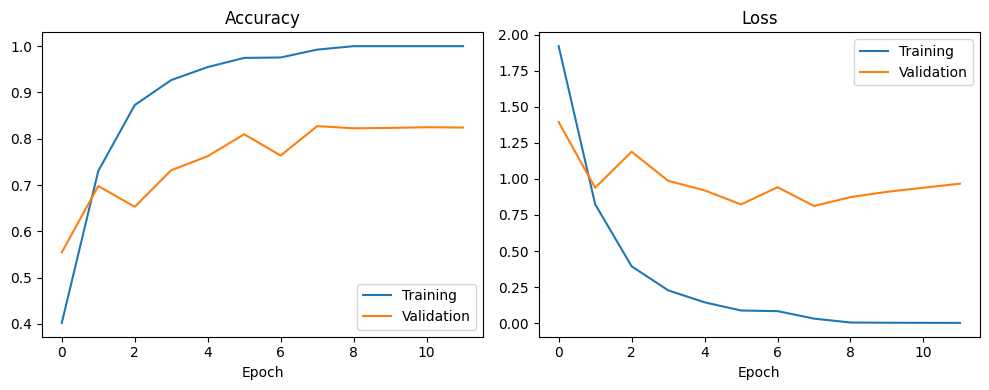

In [9]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(best_history.history["accuracy"], label="Training")
plt.plot(best_history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(best_history.history["loss"], label="Training")
plt.plot(best_history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

## 6. Evaluate once on the test half
Accuracy measures correct predictions overall. Macro F1 gives each letter equal importance. The confusion matrix shows which letters get confused. These test images were never used for training or for picking the model. Do not tune the model using these test results.

MLP (Large)              test accuracy 82.99%   macro F1 0.8135
CNN                      test accuracy 90.41%   macro F1 0.8955
SVM                      test accuracy 83.55%   macro F1 0.8188


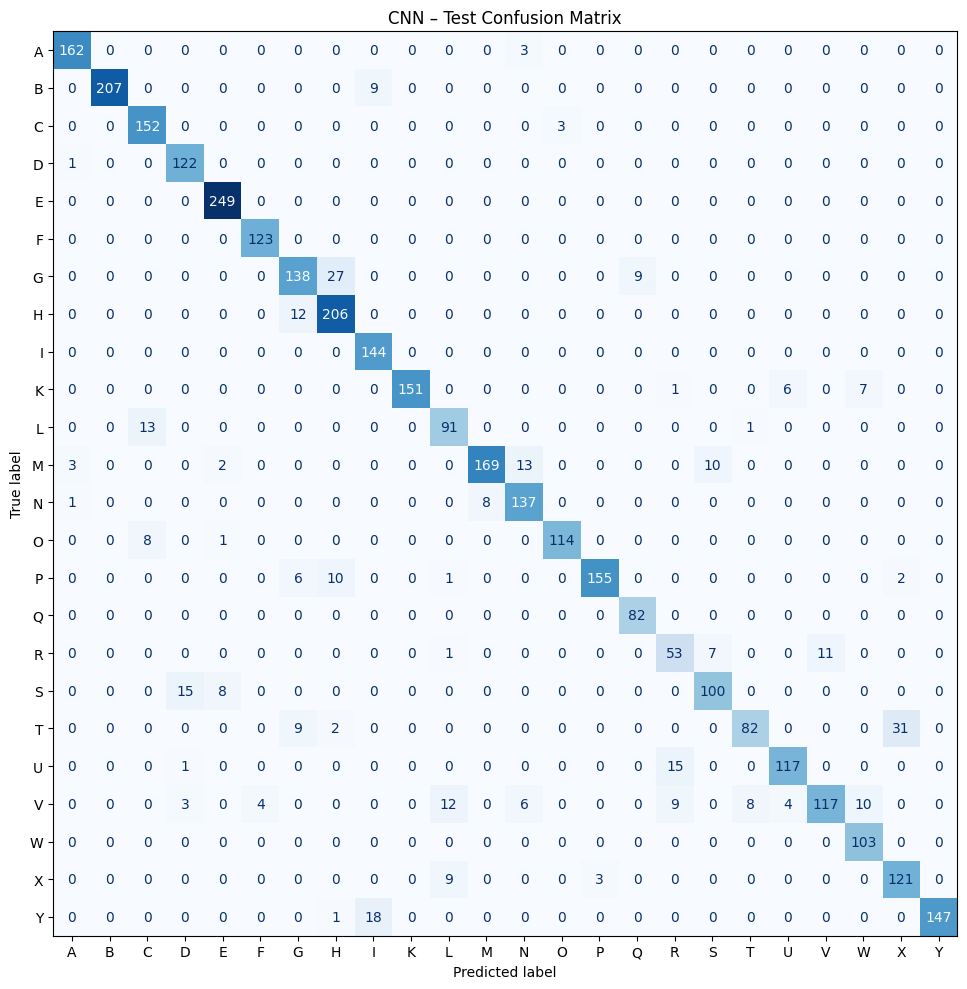

In [10]:
results_test = {
    f"MLP ({best_name})": best_model.predict(X_test, verbose=0).argmax(axis=1),
    "CNN": cnn.predict(X_test, verbose=0).argmax(axis=1),
    "SVM": svm.predict(X_test),
}
for model_name, preds in results_test.items():
    print(f"{model_name:24s} test accuracy {accuracy_score(y_test, preds):.2%}   "
          f"macro F1 {f1_score(y_test, preds, average='macro'):.4f}")

fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(y_test, results_test["CNN"],
                                        display_labels=letters, cmap="Blues",
                                        colorbar=False, ax=ax)
ax.set_title("CNN – Test Confusion Matrix")
plt.tight_layout()
plt.show()